# QM640 — RQ4 Maintenance-Cost Scenario Analysis
**Extension to existing RQ4 CAPEX prioritization notebook** · All costs, probabilities, and efficacy assumptions in this standalone notebook are **illustrative, not APSPDCL observations**.

**Research question:** Under what assumptions could AI-assisted condition-based maintenance reduce avoidable discretionary maintenance costs while preserving statutory, manufacturer-mandated, and safety-critical work?

This analysis is a *hypothetical economic comparison*, not evidence of achieved savings or a validated fault-prediction system. It does not alter your original RQ1–RQ4 findings. Replace the input table with authorized, anonymized utility observations when available.


**Updated data source:** `QM640_RQ4_Maintenance_Cost_Data.xlsx`, worksheet `Maintenance_Data`. Only seven scenario *input* columns are read; existing derived output columns in the workbook are intentionally ignored and recomputed to prevent circularity. Place the workbook beside this notebook before running.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
from pathlib import Path

OUT = Path('rq4_maintenance_outputs')
OUT.mkdir(exist_ok=True)
DISCOUNT_RATE = 0.08
YEARS = 15
BUDGET_INR = 800_000  # illustrative, optional selection constraint
annuity_factor = sum((1 + DISCOUNT_RATE)**(-year) for year in range(1, YEARS + 1))
print(f'15-year present-value annuity factor: {annuity_factor:.4f}')

15-year present-value annuity factor: 8.5595


## Inputs and assumptions
- **Mandatory maintenance** remains identical in both policies: no AI-based waiver of legal, manufacturer, or safety-critical work.
- **Discretionary scheduled maintenance** may be reduced only by the assumed fraction; remaining work is still performed.
- **AI incremental costs** include annual monitoring/diagnostics and one-time implementation. The implementation costs are illustrative and **must not be added to full transformer replacement CAPEX without checking for double counting**.
- **Failure cost** uses an illustrative annual event probability and cost per event. The model assumes AI changes that probability by a user-specified *relative* percentage; it does not infer efficacy from the DGA classifier.
- **Energy savings** are zero in this incremental maintenance-only comparison, to avoid counting energy-loss benefits already included in the existing RQ3–RQ4 model. Combine streams only after aligning baselines.


In [ ]:
# Load the supplied illustrative RQ4 Excel workbook rather than embedding numbers in code.
# Place QM640_RQ4_Maintenance_Cost_Data.xlsx in the same folder as this notebook.
DATA_FILE = Path('QM640_RQ4_Maintenance_Cost_Data.xlsx')
SHEET_NAME = 'Maintenance_Data'
INPUT_COLUMNS = [
    'rating_kva', 'mandatory_annual_inr', 'discretionary_annual_inr',
    'failure_probability_baseline', 'cost_per_failure_inr',
    'ai_annual_cost_inr', 'ai_setup_capex_inr'
]
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        f'Missing {DATA_FILE}. Download the companion Excel data file and '
        'save it in the same directory as the notebook.'
    )
raw = pd.read_excel(DATA_FILE, sheet_name=SHEET_NAME)
missing = sorted(set(INPUT_COLUMNS) - set(raw.columns))
if missing:
    raise ValueError(f'Missing required Excel columns: {missing}')
data = raw[INPUT_COLUMNS].copy()  # ignore prior calculated outputs in Excel
if data.empty or data[INPUT_COLUMNS].isna().any().any():
    raise ValueError('Input data is empty or contains missing values.')
for col in INPUT_COLUMNS:
    data[col] = pd.to_numeric(data[col], errors='raise')
if data['rating_kva'].duplicated().any() or (data['rating_kva'] <= 0).any():
    raise ValueError('Transformer ratings must be unique and positive.')
if not data['failure_probability_baseline'].between(0, 1).all():
    raise ValueError('Failure probabilities must lie between 0 and 1.')
for col in [c for c in INPUT_COLUMNS if c not in ('rating_kva', 'failure_probability_baseline')]:
    if (data[col] < 0).any():
        raise ValueError(f'Negative monetary input detected: {col}')
# Illustrative efficacy assumptions; not validated predictive-model performance.
DISCRETIONARY_REDUCTION = 0.30
RELATIVE_FAILURE_RISK_REDUCTION = 0.10
assert 0 <= DISCRETIONARY_REDUCTION <= 1
assert 0 <= RELATIVE_FAILURE_RISK_REDUCTION <= 1
print(f'Loaded {len(data)} hypothetical transformer scenarios from {DATA_FILE} [{SHEET_NAME}]')
print(data.to_string(index=False))

Loaded 6 hypothetical transformer scenarios from QM640_RQ4_Maintenance_Cost_Data.xlsx [Maintenance_Data]
 rating_kva  mandatory_annual_inr  discretionary_annual_inr  failure_probability_baseline  cost_per_failure_inr  ai_annual_cost_inr  ai_setup_capex_inr
         16                  3000                      5000                         0.045                 35000                1500               12000
         25                  3500                      6000                         0.042                 45000                1800               15000
         63                  5000                      8500                         0.040                 70000                2300               20000
        100                  6500                     11000                         0.038                 95000                2800               25000
        160                  8500                     14000                         0.035                135000                3500    

## Policy comparison and incremental NPV
For asset *i*:

- Traditional annual expected cost = mandatory + discretionary + (baseline failure probability × failure consequence).
- AI-assisted annual expected cost = mandatory + remaining discretionary + AI recurring cost + (adjusted failure probability × failure consequence).
- Annual incremental benefit = traditional cost − AI-assisted cost.
- Incremental NPV = annual incremental benefit × 15-year annuity factor − AI setup CAPEX.

A positive NPV indicates that **the hypothetical AI-maintenance program** is financially attractive under the assumptions, *not* that full transformer replacement is justified.


In [ ]:
def evaluate(df, discretionary_reduction=0.30, relative_failure_risk_reduction=0.10,
             discount_rate=0.08, years=15):
    if not 0 <= discretionary_reduction <= 1 or not 0 <= relative_failure_risk_reduction <= 1:
        raise ValueError('Reduction fractions must be in [0, 1]')
    if discount_rate < 0 or years < 1:
        raise ValueError('Discount rate must be nonnegative and years positive')
    out = df.copy()
    out['failure_probability_ai'] = out['failure_probability_baseline'] * (1 - relative_failure_risk_reduction)
    out['traditional_annual_expected_cost_inr'] = (out['mandatory_annual_inr'] + out['discretionary_annual_inr']
        + out['failure_probability_baseline'] * out['cost_per_failure_inr'])
    out['ai_annual_expected_cost_inr'] = (out['mandatory_annual_inr']
        + out['discretionary_annual_inr'] * (1 - discretionary_reduction)
        + out['ai_annual_cost_inr'] + out['failure_probability_ai'] * out['cost_per_failure_inr'])
    out['annual_incremental_benefit_inr'] = (out['traditional_annual_expected_cost_inr']
        - out['ai_annual_expected_cost_inr'])
    factor = sum((1 + discount_rate)**(-t) for t in range(1, years + 1))
    out['incremental_npv_inr'] = out['annual_incremental_benefit_inr'] * factor - out['ai_setup_capex_inr']
    out['simple_payback_years'] = np.where(out['annual_incremental_benefit_inr'] > 0,
        out['ai_setup_capex_inr'] / out['annual_incremental_benefit_inr'], np.inf)
    return out

results = evaluate(data, DISCRETIONARY_REDUCTION, RELATIVE_FAILURE_RISK_REDUCTION,
                   DISCOUNT_RATE, YEARS)
cols = ['rating_kva','traditional_annual_expected_cost_inr','ai_annual_expected_cost_inr',
        'annual_incremental_benefit_inr','ai_setup_capex_inr','incremental_npv_inr','simple_payback_years']
print(results[cols].round(2).to_string(index=False))
results.to_csv(OUT / 'illustrative_maintenance_cost_comparison.csv', index=False)

 rating_kva  traditional_annual_expected_cost_inr  ai_annual_expected_cost_inr  annual_incremental_benefit_inr  ai_setup_capex_inr  incremental_npv_inr  simple_payback_years
         16                                9575.0                       9417.5                           157.5               12000            -10651.88                 76.19
         25                               11390.0                      11201.0                           189.0               15000            -13382.26                 79.37
         63                               16300.0                      15770.0                           530.0               20000            -15463.48                 37.74
        100                               21110.0                      20249.0                           861.0               25000            -17630.29                 29.04
        160                               27225.0                      26052.5                          1172.5               35000

## Scenario sensitivity: discretionary reduction and failure-risk impact
These values are assumed and are not model performance estimates. The conservative scenario assumes **no failure-risk improvement**; the adverse scenario explicitly allows an *increase* in failure probability when discretionary work is reduced, to test safety/economic fragility. Mandatory work remains unchanged in all scenarios.


In [ ]:
scenarios = [
    ('No discretionary reduction', 0.00, 0.00),
    ('Conservative', 0.15, 0.00),
    ('Base hypothetical', 0.30, 0.10),
    ('Optimistic hypothetical', 0.45, 0.20),
    ('Adverse: failure risk rises', 0.30, -0.20),
]
rows=[]
for name, discretionary, risk in scenarios:
    # evaluate() restricts reduction to nonnegative; model adverse case by directly setting the adjusted probability.
    if risk >= 0:
        r=evaluate(data, discretionary, risk, DISCOUNT_RATE, YEARS)
    else:
        r=evaluate(data, discretionary, 0.0, DISCOUNT_RATE, YEARS)
        r['failure_probability_ai'] = np.minimum(1.0, data['failure_probability_baseline']*(1-risk))
        r['ai_annual_expected_cost_inr'] = (data['mandatory_annual_inr'] +
            data['discretionary_annual_inr']*(1-discretionary) + data['ai_annual_cost_inr'] +
            r['failure_probability_ai']*data['cost_per_failure_inr'])
        r['annual_incremental_benefit_inr'] = r['traditional_annual_expected_cost_inr'] - r['ai_annual_expected_cost_inr']
        r['incremental_npv_inr'] = r['annual_incremental_benefit_inr']*annuity_factor - data['ai_setup_capex_inr']
    rows.append({'scenario':name, 'total_incremental_npv_inr':r['incremental_npv_inr'].sum(),
                 'total_annual_incremental_benefit_inr':r['annual_incremental_benefit_inr'].sum(),
                 'positive_npv_assets':int((r['incremental_npv_inr']>0).sum())})
sensitivity=pd.DataFrame(rows)
print(sensitivity.round(2).to_string(index=False))
sensitivity.to_csv(OUT / 'illustrative_sensitivity.csv', index=False)

                   scenario  total_incremental_npv_inr  total_annual_incremental_benefit_inr  positive_npv_assets
 No discretionary reduction                 -283095.71                              -15900.0                    0
               Conservative                 -204134.52                               -6675.0                    0
          Base hypothetical                 -107874.62                                4571.0                    0
    Optimistic hypothetical                  -11614.73                               15817.0                    1
Adverse: failure risk rises                 -159770.74                               -1492.0                    0


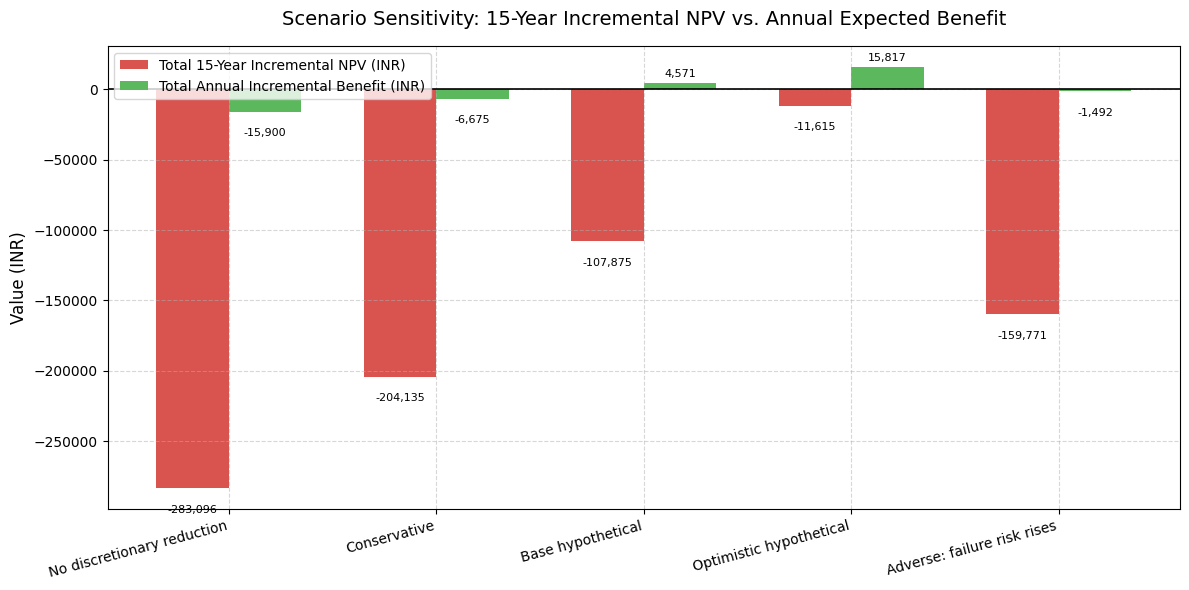

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data for plotting
scenarios_list = sensitivity['scenario'].tolist()
npv_values = sensitivity['total_incremental_npv_inr'].tolist()
annual_benefit_values = sensitivity['total_annual_incremental_benefit_inr'].tolist()

x = np.arange(len(scenarios_list))  # Label locations
width = 0.35  # Width of the bars

fig, ax = plt.subplots(figsize=(12, 6))

# Draw the grouped bars
rects1 = ax.bar(x - width/2, npv_values, width, label='Total 15-Year Incremental NPV (INR)', color='#d9534f')
rects2 = ax.bar(x + width/2, annual_benefit_values, width, label='Total Annual Incremental Benefit (INR)', color='#5cb85c')

# Graph formatting
ax.axhline(0, color='black', linestyle='-', linewidth=1.2)
ax.set_title('Scenario Sensitivity: 15-Year Incremental NPV vs. Annual Expected Benefit', fontsize=14, pad=15)
ax.set_ylabel('Value (INR)', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(scenarios_list, rotation=15, ha='right')
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, linestyle='--', alpha=0.5)

# Annotate bar values to ensure clarity
for rect in rects1 + rects2:
    height = rect.get_height()
    va_dir = 'bottom' if height >= 0 else 'top'
    offset = 3 if height >= 0 else -12
    ax.annotate(f'{height:,.0f}',
                xy=(rect.get_x() + rect.get_width() / 2, height),
                xytext=(0, offset),
                textcoords="offset points",
                ha='center', va=va_dir, fontsize=8)

fig.tight_layout()
fig.savefig(OUT / 'sensitivity_grouped_scenario_comparison.png', dpi=160)
plt.show()

## Optional budget-constrained AI monitoring rollout
The objective here is to maximize the **sum of positive incremental AI-program NPVs**, subject to the illustrative setup budget. This is distinct from the original notebook's **transformer replacement** portfolio. Do not combine their CAPEX budgets without an explicit shared-budget model.


In [ ]:
best = {'npv_inr': 0.0, 'setup_inr': 0.0, 'ratings_kva': []}
for selection in product((0,1), repeat=len(results)):
    mask=np.array(selection, dtype=bool)
    capex=float(results.loc[mask,'ai_setup_capex_inr'].sum())
    npv=float(results.loc[mask,'incremental_npv_inr'].sum())
    if capex <= BUDGET_INR and npv > best['npv_inr']:
        best={'npv_inr':npv,'setup_inr':capex,
              'ratings_kva':results.loc[mask,'rating_kva'].tolist()}
print('Illustrative AI-monitoring rollout:', best)
print('Original energy-only replacement optimization is NOT overwritten.')

Illustrative AI-monitoring rollout: {'npv_inr': 0.0, 'setup_inr': 0.0, 'ratings_kva': []}
Original energy-only replacement optimization is NOT overwritten.


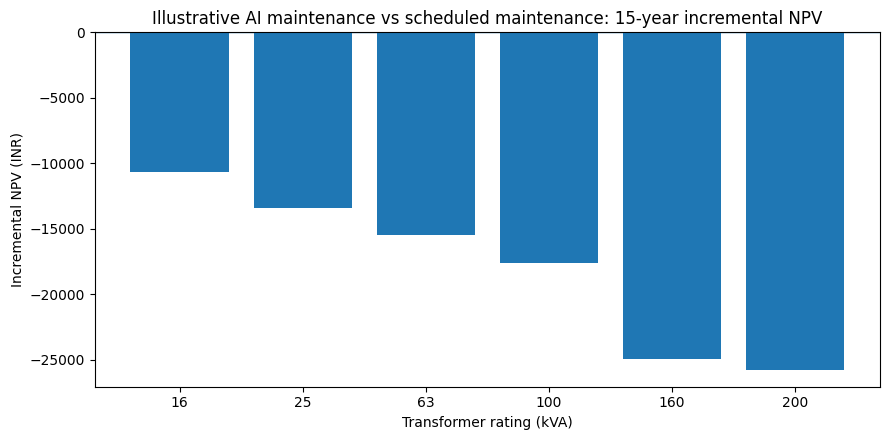

In [ ]:
fig, ax=plt.subplots(figsize=(9,4.5))
ax.bar(results['rating_kva'].astype(str), results['incremental_npv_inr'])
ax.axhline(0, linewidth=1)
ax.set(xlabel='Transformer rating (kVA)', ylabel='Incremental NPV (INR)',
       title='Illustrative AI maintenance vs scheduled maintenance: 15-year incremental NPV')
fig.tight_layout()
fig.savefig(OUT / 'maintenance_incremental_npv.png', dpi=160)
plt.show()

## Reporting guidance and limitations
**Suitable interim-report wording:** “A supplemental, explicitly hypothetical RQ4 maintenance-cost model compared scheduled maintenance with AI-assisted condition-based maintenance over a 15-year horizon at an assumed 8% discount rate. The comparison preserved mandatory maintenance in both alternatives and examined discretionary expenditure, monitoring costs, expected failure consequences, and setup CAPEX. Scenario results illustrate economic break-even conditions; they do not establish realized utility savings or field-validated AI efficacy.”

**Before field application:** obtain maintenance work orders and costs, statutory and manufacturer maintenance schedules, transformer-specific failures and consequences, monitoring and deployment costs, equipment operating conditions, and evidence of AI diagnostic effectiveness. Account for false negatives, false positives, safety and reliability constraints, and possible correlated failures. Asset-level records must be anonymized and permissions documented.

**Reproducibility:** Outputs are saved under `rq4_maintenance_outputs/` when executed. All assumptions are directly editable in the input cell. This notebook is standalone and does not modify the original RQ3–RQ4 notebook or report.


**Input reproducibility:** Re-run this notebook after editing the seven input columns in the Excel `Maintenance_Data` worksheet. The workbook also contains previously computed scenario results, but the notebook recalculates them independently. The `Sensitivity` worksheet is not used as input.


## Resources

### Why are the Incremental NPVs Negative?

The calculated 15-year incremental Net Present Values (NPV) for all transformer ratings are negative, which explains why the bar chart extends downwards below the zero baseline.

* **Cost-to-Benefit Ratio:** Under the current scenario assumptions (a 30% reduction in discretionary maintenance and a 10% reduction in failure risk), the financial savings from avoided failures and reduced discretionary work do not outweigh the implementation CAPEX and recurring annual costs of the AI-assisted system over the 15-year horizon.
* **Annuity and Setup Costs:** The upfront setup costs (such as the `ai_setup_capex_inr` starting at 12,000 to 40,000 INR) combined with annual monitoring costs consume the projected benefits, resulting in negative incremental returns across all analyzed transformer ratings.

### Detailed 5-Scenario Comparison Table

Below is the summary of aggregate 15-year incremental NPV, annual incremental benefits, and the count of positive NPV assets across the evaluated sensitivity scenarios:

In [ ]:
# Display the sensitivity summary table
display(sensitivity.round(2))

,scenario,total_incremental_npv_inr,total_annual_incremental_benefit_inr,positive_npv_assets
0,No discretionary reduction,-283095.71,-15900.0,0
1,Conservative,-204134.52,-6675.0,0
2,Base hypothetical,-107874.62,4571.0,0
3,Optimistic hypothetical,-11614.73,15817.0,1
4,Adverse: failure risk rises,-159770.74,-1492.0,0
